# Environment and Import

In [167]:
pip install pandas sklearn matplotlib missingno

  error: subprocess-exited-with-error
  
  × python setup.py egg_info did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
      More information is available at
      https://github.com/scikit-learn/sklearn-pypi-packag


  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'error'


In [168]:
import os
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import missingno as msno

# Load and Check Data
Also includes universal transformations

In [169]:


data_folder = '../data'
data_files = [f for f in os.listdir(data_folder) if f.endswith('.csv')]
data_dict = {}

for file in data_files:
    file_path = os.path.join(data_folder, file)
    df_name = os.path.splitext(file)[0]
    data_dict[df_name] = pd.read_csv(file_path)


In [170]:
for df_name, df in data_dict.items():
    print(f"{df_name}: {df.shape}")

birth_district_sex: (1401, 6)
crime_district: (19152, 6)
gdp_district_real_supply: (10626, 6)
hh_income_district: (318, 5)
missing_rows: (870, 8)
population_district: (319200, 7)


In [171]:
for df_name, df in data_dict.items():
    print(f"Head of {df_name}:")
    print(df.head())
    print("\n")


Head of birth_district_sex:
         date  state     district     sex    abs       rate
0  2020-01-01  Johor   Batu Pahat    both   6653  13.432263
1  2020-01-01  Johor   Batu Pahat  female   3236  13.846812
2  2020-01-01  Johor   Batu Pahat    male   3417  13.061927
3  2020-01-01  Johor  Johor Bahru    both  24675  14.419705
4  2020-01-01  Johor  Johor Bahru  female  11954  14.870009


Head of crime_district:
      state district category type        date  crimes
0  Malaysia      All  assault  all  2016-01-01   22327
1  Malaysia      All  assault  all  2017-01-01   21366
2  Malaysia      All  assault  all  2018-01-01   16902
3  Malaysia      All  assault  all  2019-01-01   16489
4  Malaysia      All  assault  all  2020-01-01   13279


Head of gdp_district_real_supply:
  series  state    district        date sector       value
0    abs  Johor  Batu Pahat  2015-01-01     p0  11605.5017
1    abs  Johor  Batu Pahat  2015-01-01     p1   2177.2570
2    abs  Johor  Batu Pahat  2015-01-01    

In [172]:
import re

for df_name, df in data_dict.items():
    # Create a year column from the first date column found
    date_columns = [col for col in df.columns if re.search(r'\d{4}-\d{2}-\d{2}', str(df[col].iloc[0]))]
    if date_columns:
        df['year'] = pd.to_datetime(df[date_columns[0]]).dt.year
    
    # Drop all date columns
    df.drop(columns=date_columns, inplace=True)


In [173]:
for df_name, df in data_dict.items():
    print(f"Head of {df_name}:")
    print(df.head())
    print("\n")

Head of birth_district_sex:
   state     district     sex    abs       rate  year
0  Johor   Batu Pahat    both   6653  13.432263  2020
1  Johor   Batu Pahat  female   3236  13.846812  2020
2  Johor   Batu Pahat    male   3417  13.061927  2020
3  Johor  Johor Bahru    both  24675  14.419705  2020
4  Johor  Johor Bahru  female  11954  14.870009  2020


Head of crime_district:
      state district category type  crimes  year
0  Malaysia      All  assault  all   22327  2016
1  Malaysia      All  assault  all   21366  2017
2  Malaysia      All  assault  all   16902  2018
3  Malaysia      All  assault  all   16489  2019
4  Malaysia      All  assault  all   13279  2020


Head of gdp_district_real_supply:
  series  state    district sector       value  year
0    abs  Johor  Batu Pahat     p0  11605.5017  2015
1    abs  Johor  Batu Pahat     p1   2177.2570  2015
2    abs  Johor  Batu Pahat     p2     13.0113  2015
3    abs  Johor  Batu Pahat     p3   3255.7651  2015
4    abs  Johor  Batu Pahat

# Crime District Transformation

## Massaging

In [174]:
print(len(df))

df = data_dict['crime_district']
dff = df[df['type'] == 'all']
dff = dff[dff['district'] != 'All']
dff = dff[dff['state'] != 'Malaysia']

columns = dff.columns.tolist()
columns.remove('district')
columns.remove('year')

# Group by 'district' and 'year', take the first of every column and sum of 'crimes' column
grouped_dff = dff.groupby(['district', 'year']).agg({col: 'first' if col != 'crimes' and col != 'year' else 'sum' for col in columns}).reset_index()

del grouped_dff['category'], grouped_dff['type']

massaged_dict = {}
massaged_dict['crime_district'] = grouped_dff

print(len(grouped_dff))

319200
1248


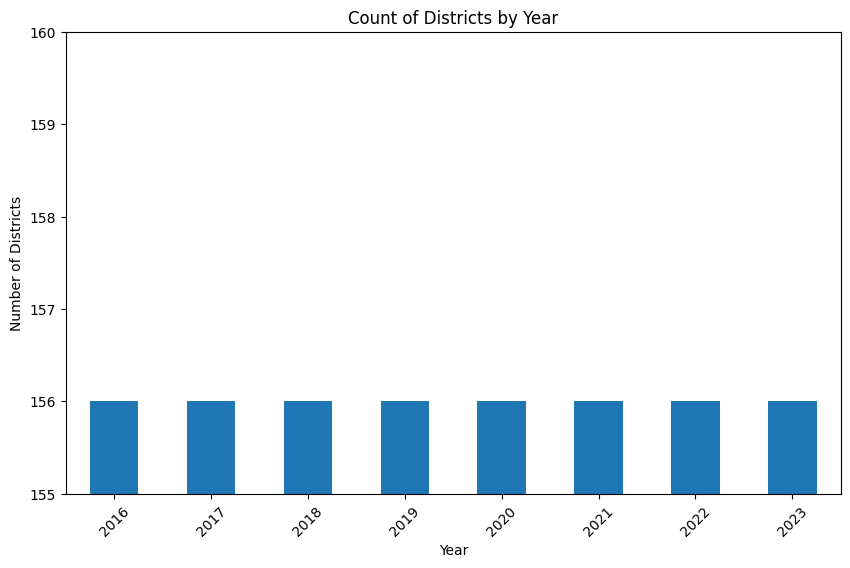

In [175]:
import matplotlib.pyplot as plt

# Count the number of districts by year
district_counts = grouped_dff.groupby('year')['district'].nunique()

# Plot the bar chart
plt.figure(figsize=(10, 6))
district_counts.plot(kind='bar')
plt.title('Count of Districts by Year')
plt.xlabel('Year')
plt.ylabel('Number of Districts')
plt.ylim(155,160)
plt.xticks(rotation=45)
plt.show()



In [176]:
# Clean the 'district' column
grouped_dff['district'] = grouped_dff['district'].replace({
    'Sg. Buloh': 'Sungai Buloh',
    'Cameron Highland': 'Cameron Highlands',
    'Bandar Bharu': 'Bandar Baharu'
})

In [177]:
grouped_dff.district.value_counts()[grouped_dff.district.value_counts() < 8].index.tolist()

[]

In [178]:
# Districts has been cleaned

In [179]:
# Find the districts that are not shared across all data
all_districts = set()
shared_districts = None
districts_not_in_dfs = {}
crime_districts = set()
other_districts = set()

# Separate districts in crime data and other data
for key, df in data_dict.items():
    if 'district' in df.columns:
        districts = set(df['district'].unique())
        all_districts.update(districts)
        if key == 'crime':
            crime_districts = districts
        else:
            other_districts.update(districts)
        if shared_districts is None:
            shared_districts = districts
        else:
            shared_districts &= districts
    else:
        print(f"Dataframe '{key}' does not have a 'district' column")

if shared_districts is not None:
    not_shared_districts = all_districts - shared_districts
else:
    not_shared_districts = all_districts

# Identify which dataframes don't have the not shared districts
for district in not_shared_districts:
    districts_not_in_dfs[district] = []
    for key, df in data_dict.items():
        if 'district' in df.columns and district not in df['district'].unique():
            districts_not_in_dfs[district].append(key)

# Separate reporting
crime_not_in_others = crime_districts - other_districts
others_not_in_crime = other_districts - crime_districts
unique_districts = not_shared_districts

# Adjust the reporting based on the instruction
all_not_in_others = {district for district, dfs in districts_not_in_dfs.items() if set(dfs) == {'birth_district_sex', 'hh_income_district', 'population_district'}}
in_four_not_crime = {district for district, dfs in districts_not_in_dfs.items() if len(dfs) == 4 and 'crime' not in dfs}

# Print the reports
print(f"Districts in crime data but not in others ({len(crime_not_in_others)}): {', '.join(crime_not_in_others)}")

print(f"Districts in other data but not in crime ({len(others_not_in_crime)}): {', '.join(others_not_in_crime)}")

print(f"Districts not shared across all data ({len(unique_districts)}):")
for district, dfs in districts_not_in_dfs.items():
    print(f"{district}: not in {', '.join(dfs)}")

print(f"Districts not in birth_district_sex, hh_income_district, population_district ({len(all_not_in_others)}): {', '.join(all_not_in_others)}")

print(f"Districts in 4 datasets but not in crime ({len(in_four_not_crime)}): {', '.join(in_four_not_crime)}")


Districts in crime data but not in others (0): 
Districts in other data but not in crime (209): Tampin, Pokok Sena, Simunjan, Ipoh, All, Pakan, Dang Wangi, Telang Usan, Kuala Pilah, Kota Kinabalu, Tapah, Kuala Krai, Marang, Kangar, Pasir Mas, Sungai Siput, Ranau, Mersing, Tambunan, Tebedu, Kuala Kangsar, Semporna, Cameron Highland, Tanah Merah, Ampang Jaya, Kuala Lipis, Kota Kinabatangan, Kuala Selangor, Serian, Raub, Saratok, Asajaya, Kalabakan, Padawan, Kecil Lojing, Sebauh, Larut dan Matang, Kota Samarahan, Keningau, Hulu Terengganu, Dungun, Seberang Perai Utara, Arau, Penampang, Bintulu, Kerian, Tawau, Bandar Bharu, Batu Pahat, Perak Tengah, Perlis, Hilir Perak, Nusajaya, Jeli, Kinabatangan, Langkawi, Bandar Baharu, Sri Aman, Hulu Perak, Ulu Selangor, Batang Padang, Limbang, Serdang, Kuala Langat, Pendang, Gombak, Alor Gajah, Kulai, Sik, Rembau, Tangkak, Machang, Kudat, Tanjung Manis, Nilai, Hulu Selangor, Petaling Jaya, Sibu, Port Dickson, Kulim, Daro, Lawas, Kuala Penyu, Tumpat, 

In [180]:
# Report how many districts are consistent across all data in data_dict
if shared_districts is not None:
    consistent_districts_count = len(shared_districts)
else:
    consistent_districts_count = 0

print(f"Number of districts consistent across all data: {consistent_districts_count}")


Number of districts consistent across all data: 115


In [181]:
# Assuming 'crime' is the key for the crime dataframe in grouped_dff
if 'crime' in grouped_dff:
    massaged_crime_df = grouped_dff['crime']
    print("Massaged Crime DataFrame:")
    print(massaged_crime_df)
else:
    print("Crime data is not available in the grouped data.")



Crime data is not available in the grouped data.


In [182]:
df_crime = grouped_dff
df_crime.shape, df_crime.head()

((1248, 4),
      district  year   state  crimes
 0  Alor Gajah  2016  Melaka     436
 1  Alor Gajah  2017  Melaka     376
 2  Alor Gajah  2018  Melaka     334
 3  Alor Gajah  2019  Melaka     341
 4  Alor Gajah  2020  Melaka     265)

In [183]:
df_crime.year.unique()

array([2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])

## Extrapolation

            district  year              state       crimes
0         Alor Gajah  2015             Melaka   423.821429
9         Alor Gajah  2024             Melaka   212.428571
10       Ampang Jaya  2015           Selangor  3325.607143
19       Ampang Jaya  2024           Selangor   597.642857
20              Arau  2015             Perlis   164.250000
...              ...   ...                ...          ...
1539  W.P. Putrajaya  2024  W.P. Kuala Lumpur  -118.500000
1540     Wangsa Maju  2015  W.P. Kuala Lumpur  3653.321429
1549     Wangsa Maju  2024  W.P. Kuala Lumpur    87.928571
1550             Yan  2015              Kedah   162.857143
1559             Yan  2024              Kedah    71.142857

[312 rows x 4 columns]


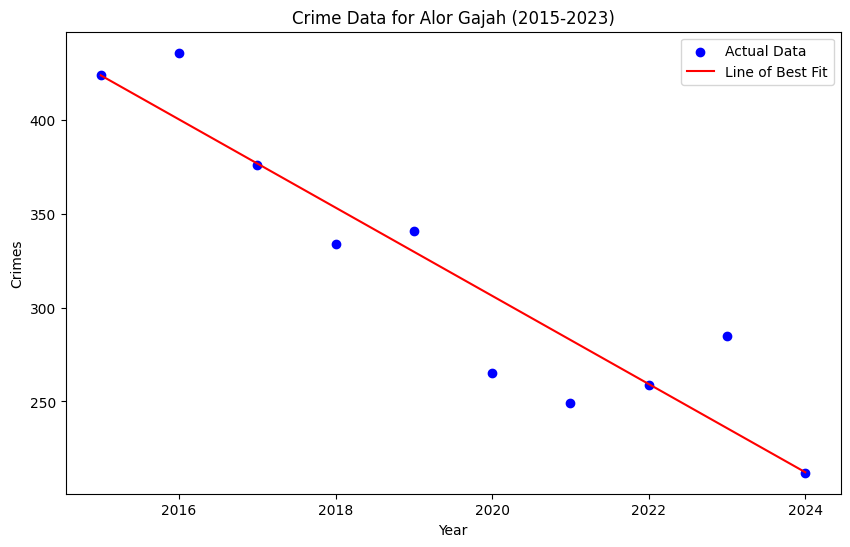

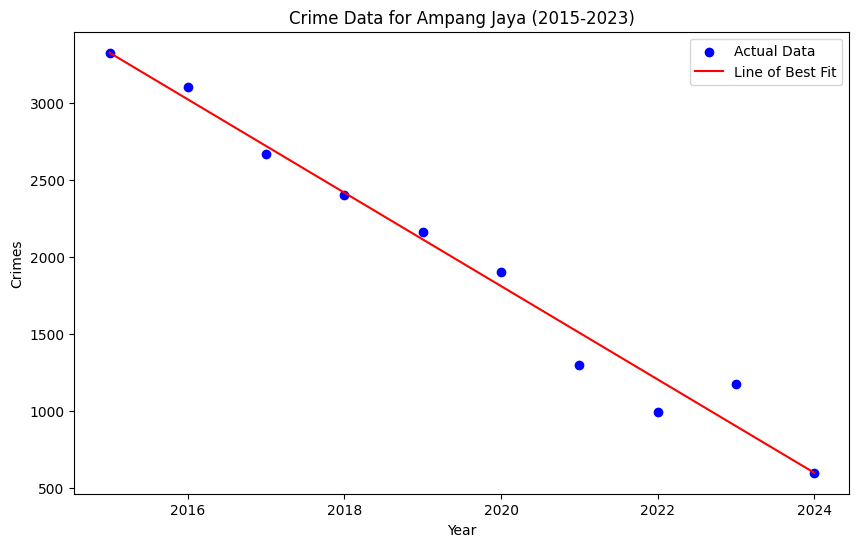

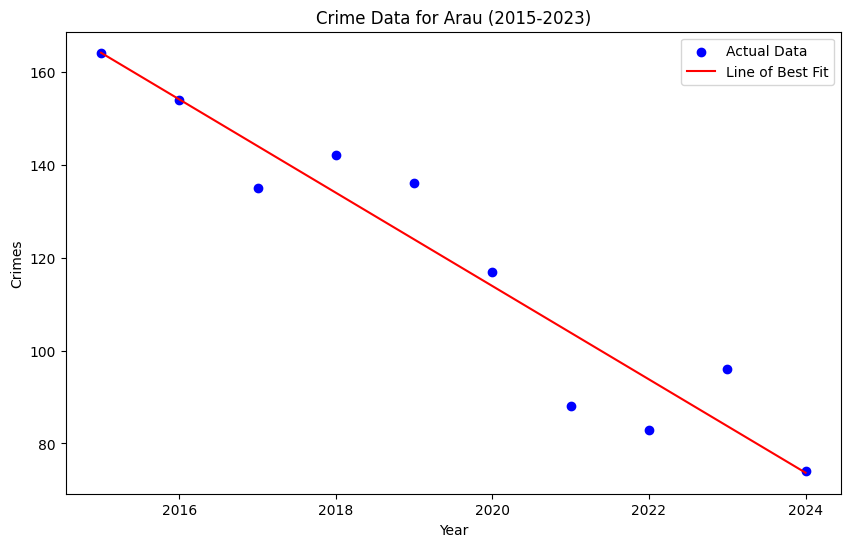

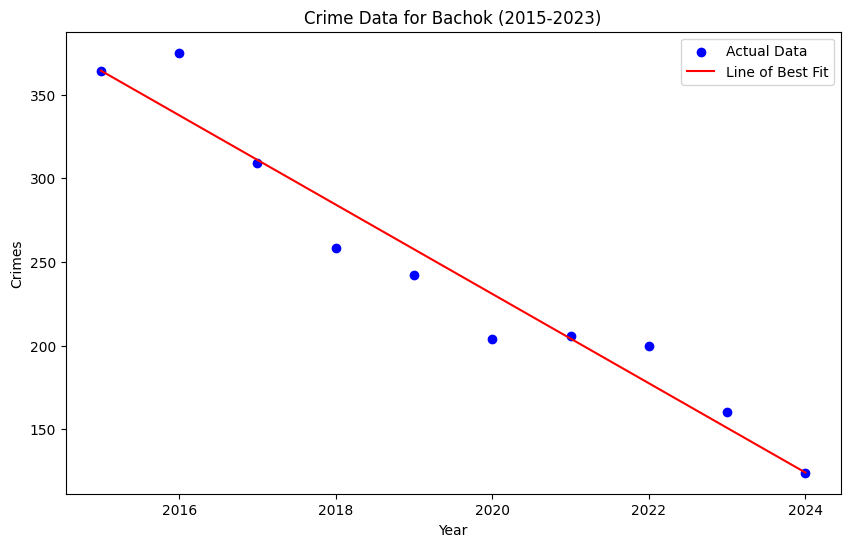

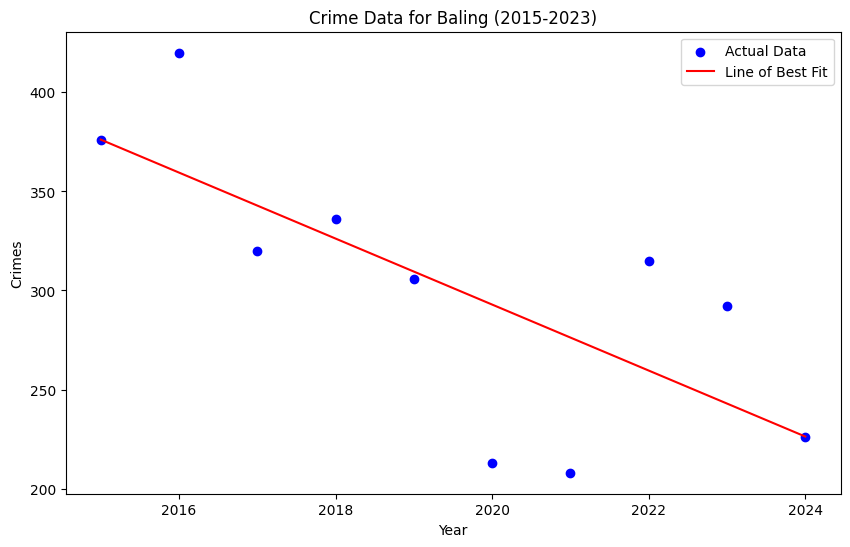

(array([2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024],
       dtype=int64),
      district  year   state  crimes
 0  Alor Gajah  2015  Melaka     424
 1  Alor Gajah  2016  Melaka     436
 2  Alor Gajah  2017  Melaka     376
 3  Alor Gajah  2018  Melaka     334
 4  Alor Gajah  2019  Melaka     341)

In [184]:
# Assuming 'df_crime' is the DataFrame containing the crime data
# We will use linear regression to extrapolate the years 2015 and 2024 based on the data from 2016 to 2023

# Prepare the data for linear regression
years = np.array([2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]).reshape(-1, 1)

# Create a new DataFrame to store the extrapolated data
extrapolated_data = []

for district in df_crime['district'].unique():
    district_data = df_crime[df_crime['district'] == district]
    if len(district_data) == len(years):  # Ensure we have data for all years
        crimes = district_data['crimes'].values
        model = LinearRegression()
        model.fit(years, crimes)
        crime_2015 = round(model.predict(np.array([[2015]]))[0], 6)  # Keep as floating point with 6 decimal places
        crime_2024 = round(model.predict(np.array([[2024]]))[0], 6)  # Extrapolate for 2024
        # Ensure only one data point per year per district
        extrapolated_data.append([district, 2015, district_data['state'].iloc[0], crime_2015])
        extrapolated_data.append([district, 2024, district_data['state'].iloc[0], crime_2024])

# Convert the extrapolated data to a DataFrame
extrapolated_df = pd.DataFrame(extrapolated_data, columns=['district', 'year', 'state', 'crimes'])

# Append the extrapolated data to the original DataFrame
df_crime = pd.concat([df_crime, extrapolated_df], ignore_index=True)

# Remove duplicate entries for the year 2015
df_crime = df_crime.drop_duplicates(subset=['district', 'year'])

# Sort the final DataFrame by district and year
df_crime = df_crime.sort_values(by=['district', 'year']).reset_index(drop=True)

# Verify the result
print(df_crime[df_crime['year'].isin([2015, 2024])])

# Round the 'crimes' column to the nearest integer
df_crime['crimes'] = df_crime['crimes'].round().astype(int)

# Plot the first 5 districts from 2015 to 2023 with a line of best fit

first_5_districts = df_crime['district'].unique()[:5]
for district in first_5_districts:
    district_data = df_crime[(df_crime['district'] == district) & (df_crime['year'] <= 2024)]
    plt.figure(figsize=(10, 6))
    plt.scatter(district_data['year'], district_data['crimes'], color='blue', label='Actual Data')
    
    # Fit the model again for plotting
    model.fit(district_data['year'].values.reshape(-1, 1), district_data['crimes'].values)
    plt.plot(district_data['year'], model.predict(district_data['year'].values.reshape(-1, 1)), color='red', label='Line of Best Fit')
    
    plt.title(f'Crime Data for {district} (2015-2023)')
    plt.xlabel('Year')
    plt.ylabel('Crimes')
    plt.legend()
    plt.show()

df_crime.year.unique(), df_crime.head()

## Final Check

In [185]:
df_crime.year.unique()

array([2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024],
      dtype=int64)

In [186]:
len(df_crime.district.unique()), df_crime.district.unique()[:3], df_crime.district.unique()[-3:]

(156,
 array(['Alor Gajah', 'Ampang Jaya', 'Arau'], dtype=object),
 array(['W.P. Putrajaya', 'Wangsa Maju', 'Yan'], dtype=object))

In [187]:
# Is the data from 2015 to 2024? - Yes
# Is the data of districts 'Alor Gajah', 'Ampang Jaya', 'Arau', ..., 'W.P. Putrajaya', 'Wangsa Maju', 'Yan'? - Yes
# Can the data be joined by district and year, while retaining the same length? - Yes

In [188]:
df_crime.to_csv('../data/massaged/crime.csv', index=False)

# GDP Transformation

## Massaging

In [189]:
df_gdp = data_dict['gdp_district_real_supply']

In [190]:
df_gdp.shape, df_gdp.head()

((10626, 6),
   series  state    district sector       value  year
 0    abs  Johor  Batu Pahat     p0  11605.5017  2015
 1    abs  Johor  Batu Pahat     p1   2177.2570  2015
 2    abs  Johor  Batu Pahat     p2     13.0113  2015
 3    abs  Johor  Batu Pahat     p3   3255.7651  2015
 4    abs  Johor  Batu Pahat     p4    109.0029  2015)

In [191]:
df_gdp = df_gdp[df_gdp['series'] == 'abs']
del df_gdp['series']

In [192]:
df_gdp.shape, df_gdp.head()

((5796, 5),
    state    district sector       value  year
 0  Johor  Batu Pahat     p0  11605.5017  2015
 1  Johor  Batu Pahat     p1   2177.2570  2015
 2  Johor  Batu Pahat     p2     13.0113  2015
 3  Johor  Batu Pahat     p3   3255.7651  2015
 4  Johor  Batu Pahat     p4    109.0029  2015)

In [193]:
df_gdp.isna().sum()

state         0
district      0
sector        0
value       507
year          0
dtype: int64

In [194]:
df_gdp = df_gdp.pivot_table(index=['state', 'district', 'year'], columns='sector', values='value').reset_index()
df_gdp.columns.name = None
df_gdp.reset_index(drop=True, inplace=True)
(df_gdp.isna().sum() / len(df_gdp)) * 100

state        0.000000
district     0.000000
year         0.000000
p0           0.000000
p1           0.621118
p2          22.049689
p3          10.455487
p4          19.358178
p5           0.000000
dtype: float64

In [195]:
df_gdp.head()

,state,district,year,p0,p1,p2,p3,p4,p5
0,Johor,Batu Pahat,2015,11605.5017,2177.2570,13.0113,3255.7651,109.0029,5915.2628
1,Johor,Batu Pahat,2016,12278.8487,2226.4352,15.7649,3460.4801,159.6552,6225.9917
2,Johor,Batu Pahat,2017,13115.0995,2333.1613,18.5291,3802.4955,161.2386,6590.7041
3,Johor,Batu Pahat,2018,13689.4696,2376.1347,19.1149,3963.5969,141.7790,7003.0581
4,Johor,Batu Pahat,2019,14499.0001,2519.2094,20.0645,4194.7808,157.0281,7425.8420


In [196]:
# Decision to remove columns with more than 10% missingness
del df_gdp['p2'], df_gdp['p4']

# Sectors removed are mining & quarrying, and manufacturing

<Axes: >

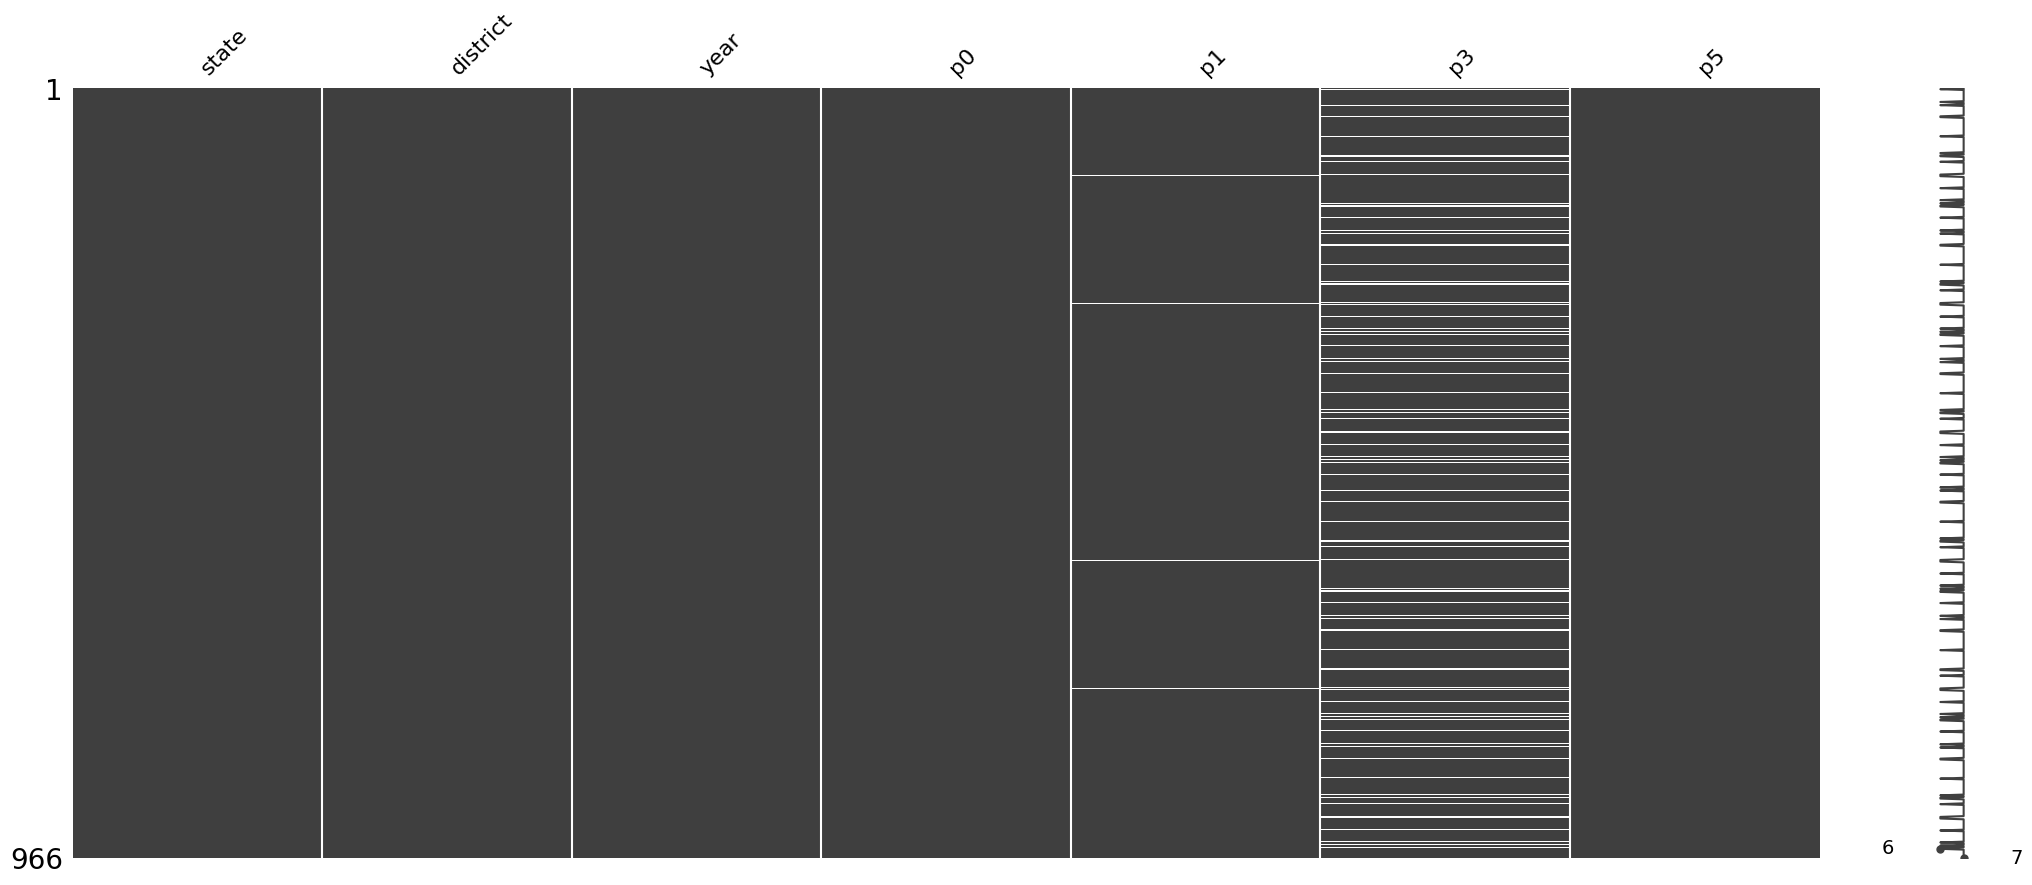

In [197]:
df_gdp = df_gdp.sort_values(by=['year', 'district'])
msno.matrix(df_gdp)

In [198]:
na_indices = df_gdp[df_gdp.isna().any(axis=1)].index
df_gdp[df_gdp.isna().any(axis=1)]

,state,district,year,p0,p1,p3,p5
606,Sarawak,Asajaya,2015,326.6131,206.6166,NaN,98.8030
630,Sarawak,Betong,2015,508.8049,296.7046,NaN,156.3752
648,Sarawak,Dalat,2015,290.1075,227.0044,NaN,60.6265
660,Sarawak,Julau,2015,104.4469,54.9058,NaN,48.3141
666,Sarawak,Kabong,2015,53.6462,10.7540,NaN,42.2265
...,...,...,...,...,...,...,...
785,Sarawak,Selangau,2020,209.3725,113.5160,NaN,92.4410
575,Sabah,Tambunan,2020,151.1283,40.3570,NaN,107.5805
833,Sarawak,Tanjung Manis,2020,148.5180,70.8034,NaN,54.6042
845,Sarawak,Tebedu,2020,71.1730,14.8598,NaN,55.8583


In [199]:
# value counts for state district year

In [200]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import LabelEncoder

# Unique label encoder for each column
state_le = LabelEncoder()
district_le = LabelEncoder()
year_le = LabelEncoder()

df_gdp['state'] = state_le.fit_transform(df_gdp['state'])
df_gdp['district'] = district_le.fit_transform(df_gdp['district'])
df_gdp['year'] = year_le.fit_transform(df_gdp['year'])

# KNN imputation for missing values
imputer = KNNImputer(n_neighbors=5)
df_gdp_imputed = pd.DataFrame(imputer.fit_transform(df_gdp), columns=df_gdp.columns)

In [201]:
df_gdp_imputed.isna().sum()

state       0
district    0
year        0
p0          0
p1          0
p3          0
p5          0
dtype: int64

In [202]:
df_gdp_imputed.loc[na_indices]

,state,district,year,p0,p1,p3,p5
606,0.0,123.0,3.0,4935.4798,1527.3314,654.63470,2623.6727
630,10.0,146.0,3.0,69.2373,13.8679,0.00000,54.9984
648,1.0,4.0,4.0,1539.4039,413.8132,218.75850,863.2999
660,12.0,16.0,4.0,2158.4064,333.0379,291.47450,1460.9666
666,10.0,22.0,4.0,508.4328,347.7501,23.05460,114.9251
...,...,...,...,...,...,...,...
785,4.0,140.0,4.0,2338.8304,498.1743,372.03300,1356.5808
575,9.0,92.0,3.0,313.9751,209.7918,8.31592,101.8168
833,12.0,28.0,5.0,1311.9714,370.7322,65.41210,821.1313
845,10.0,40.0,5.0,1596.1039,1217.4249,33.85910,183.1993


<Axes: >

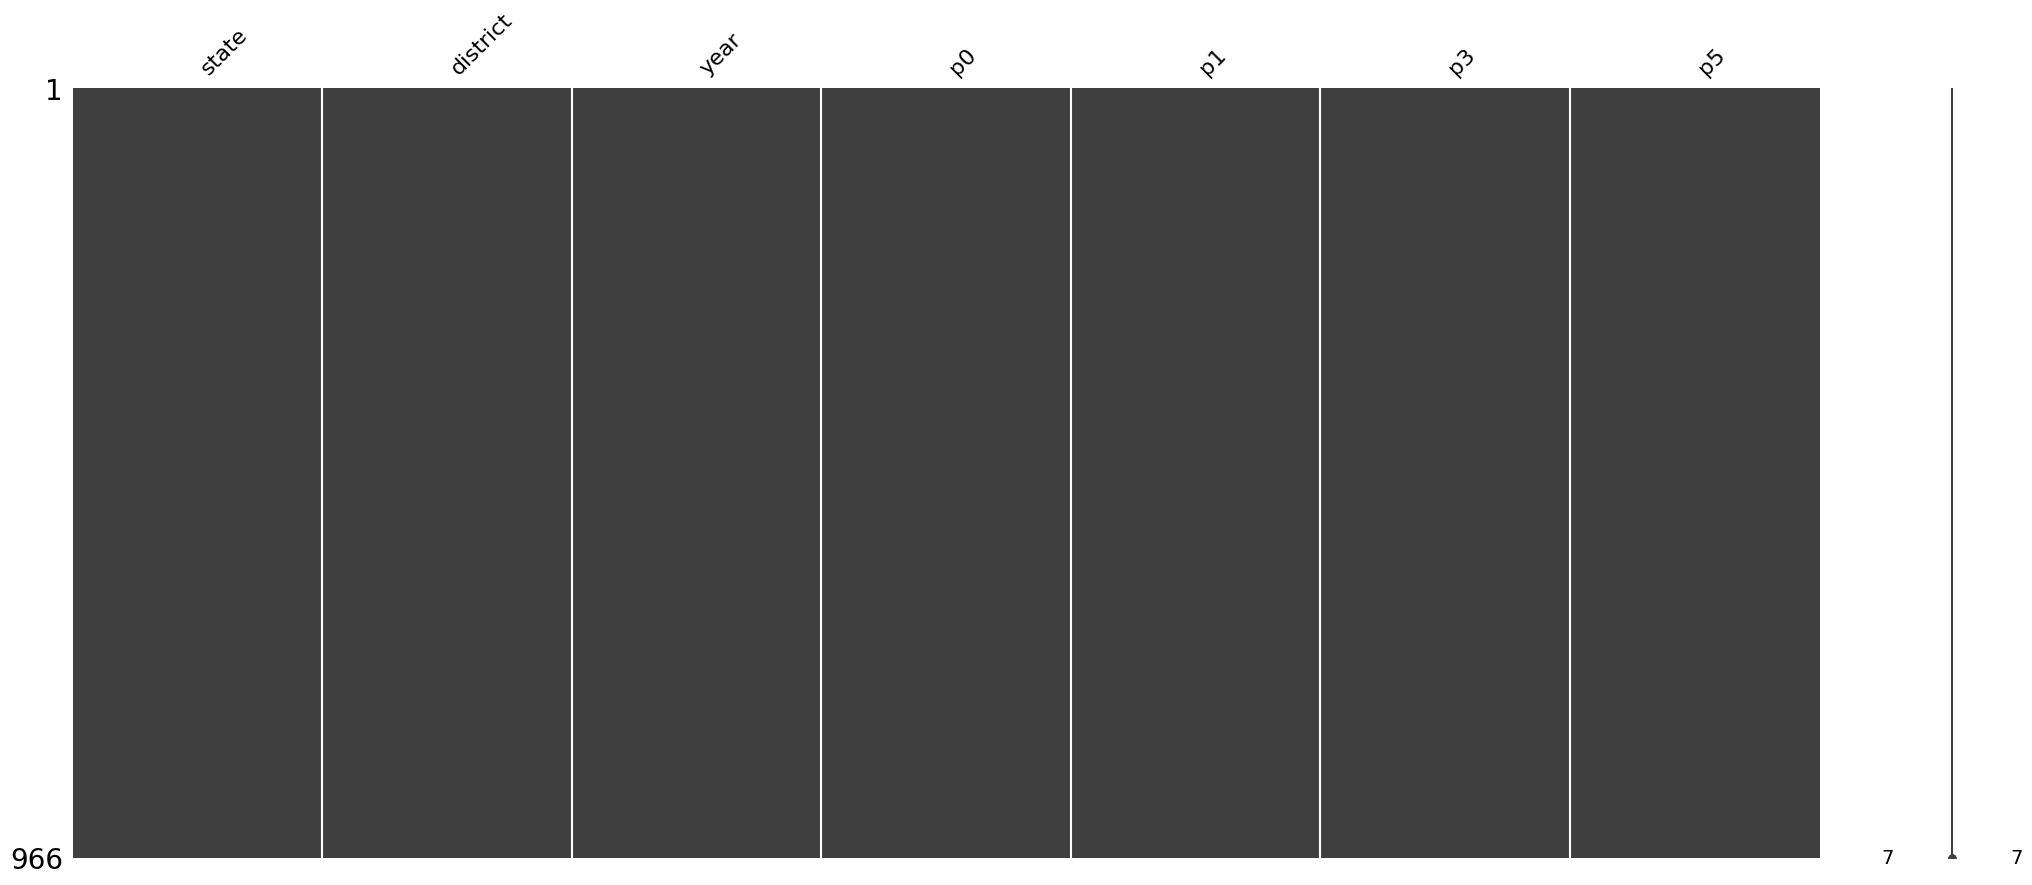

In [203]:
df_gdp_imputed = df_gdp_imputed.sort_values(by=['year', 'district'])
msno.matrix(df_gdp_imputed)

In [204]:
# Decode the label encoding for df_gdp_imputed
df_gdp_imputed['state'] = state_le.inverse_transform(df_gdp_imputed['state'].astype(int))
df_gdp_imputed['district'] = district_le.inverse_transform(df_gdp_imputed['district'].astype(int))
df_gdp_imputed['year'] = year_le.inverse_transform(df_gdp_imputed['year'].astype(int))

In [205]:
df_gdp_imputed.year.unique()

array([2015, 2016, 2017, 2018, 2019, 2020])

In [206]:
df_gdp_imputed.head()

,state,district,year,p0,p1,p3,p5
0,Melaka,Alor Gajah,2015,8856.3908,1655.7418,3946.0166,3081.0487
1,Sarawak,Asajaya,2015,326.6131,206.6166,8.5286,98.8030
2,Kelantan,Bachok,2015,1477.4222,726.8712,10.7435,729.7303
3,Perak,Bagan Datuk,2015,2672.1442,1478.8876,358.8963,817.6034
4,Kedah,Baling,2015,1395.3451,434.7939,194.1093,719.3754


In [207]:
df_gdp_imputed.columns = ['state', 'district', 'year', 'gdp_purchasers', 'gdp_agriculture', 'gdp_manufacturing', 'gdp_services']
df_gdp_imputed.head()

,state,district,year,gdp_purchasers,gdp_agriculture,gdp_manufacturing,gdp_services
0,Melaka,Alor Gajah,2015,8856.3908,1655.7418,3946.0166,3081.0487
1,Sarawak,Asajaya,2015,326.6131,206.6166,8.5286,98.8030
2,Kelantan,Bachok,2015,1477.4222,726.8712,10.7435,729.7303
3,Perak,Bagan Datuk,2015,2672.1442,1478.8876,358.8963,817.6034
4,Kedah,Baling,2015,1395.3451,434.7939,194.1093,719.3754


In [208]:
df_gdp = df_gdp_imputed

In [209]:
df_gdp.isna().sum()

state                0
district             0
year                 0
gdp_purchasers       0
gdp_agriculture      0
gdp_manufacturing    0
gdp_services         0
dtype: int64

## Extrapolation

In [210]:
# Check for infinite values in the DataFrame
infinite_values = df_gdp.isin([np.inf, -np.inf]).sum()
print(infinite_values)

state                0
district             0
year                 0
gdp_purchasers       0
gdp_agriculture      0
gdp_manufacturing    0
gdp_services         0
dtype: int64


In [211]:
df_gdp.head()

,state,district,year,gdp_purchasers,gdp_agriculture,gdp_manufacturing,gdp_services
0,Melaka,Alor Gajah,2015,8856.3908,1655.7418,3946.0166,3081.0487
1,Sarawak,Asajaya,2015,326.6131,206.6166,8.5286,98.8030
2,Kelantan,Bachok,2015,1477.4222,726.8712,10.7435,729.7303
3,Perak,Bagan Datuk,2015,2672.1442,1478.8876,358.8963,817.6034
4,Kedah,Baling,2015,1395.3451,434.7939,194.1093,719.3754


In [212]:
df_gdp.dtypes

state                 object
district              object
year                   int32
gdp_purchasers       float64
gdp_agriculture      float64
gdp_manufacturing    float64
gdp_services         float64
dtype: object

            state     district  year  gdp_purchasers  gdp_agriculture  \
6          Melaka   Alor Gajah  2021    11829.411140              NaN   
7          Melaka   Alor Gajah  2022    12262.454537              NaN   
8          Melaka   Alor Gajah  2023    12695.497934              NaN   
9          Melaka   Alor Gajah  2024    13128.541331              NaN   
16        Sarawak      Asajaya  2021      339.401987              NaN   
...           ...          ...   ...             ...              ...   
1599  W.P. Labuan  W.P. Labuan  2024     9205.303019              NaN   
1606        Kedah          Yan  2021      772.062300              NaN   
1607        Kedah          Yan  2022      791.531243              NaN   
1608        Kedah          Yan  2023      811.000186              NaN   
1609        Kedah          Yan  2024      830.469129              NaN   

      gdp_manufacturing  gdp_services  
6                   NaN           NaN  
7                   NaN           NaN  
8  

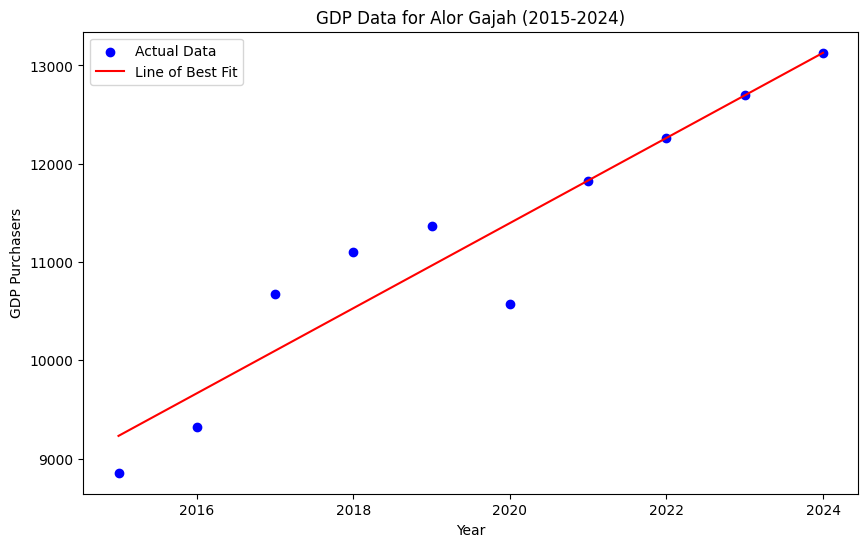

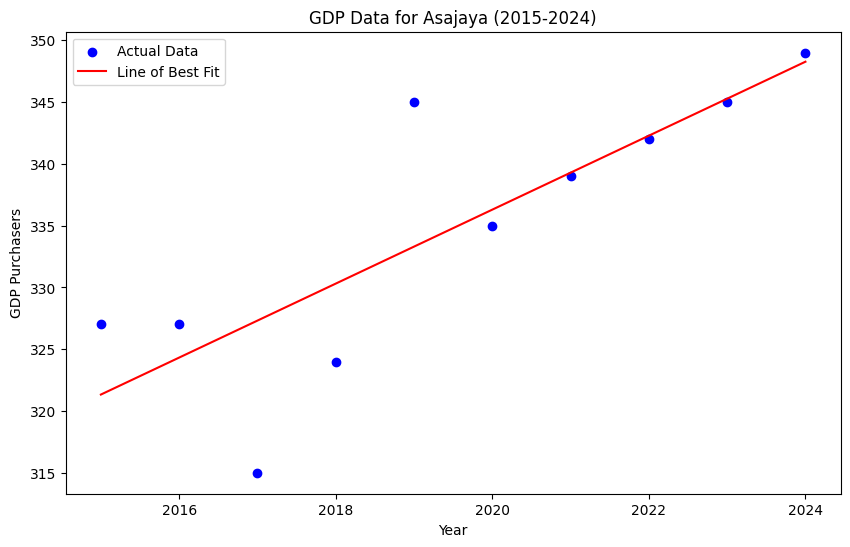

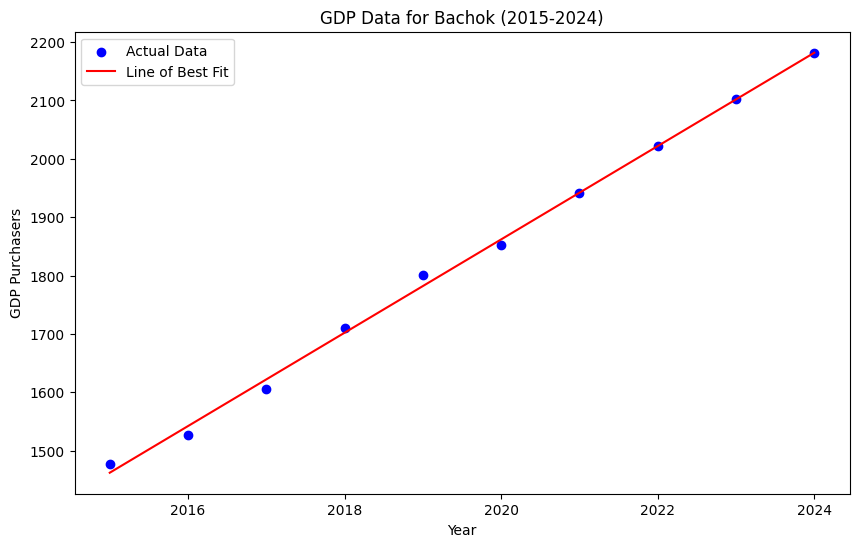

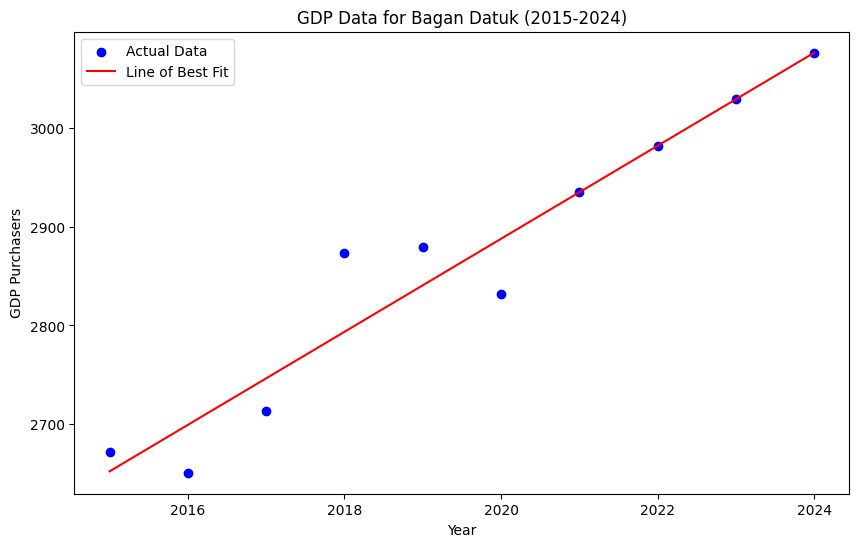

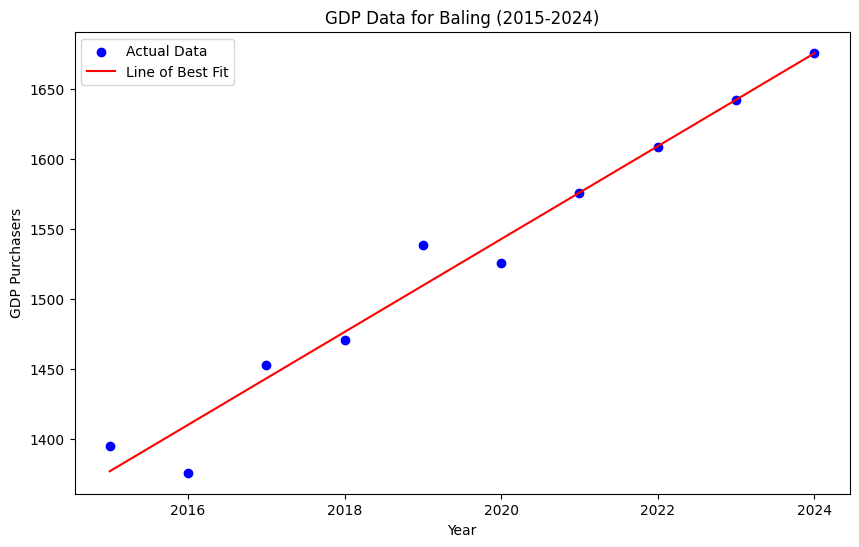

(array([2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024],
       dtype=int64),
     state    district  year  gdp_purchasers  gdp_agriculture  \
 0  Melaka  Alor Gajah  2015            8856        1655.7418   
 1  Melaka  Alor Gajah  2016            9317        1700.6370   
 2  Melaka  Alor Gajah  2017           10672        1833.6074   
 3  Melaka  Alor Gajah  2018           11098        1831.3836   
 4  Melaka  Alor Gajah  2019           11363        1830.4535   
 
    gdp_manufacturing  gdp_services  
 0          3946.0166     3081.0487  
 1          4189.6478     3256.4936  
 2          4645.5616     3436.0245  
 3          4914.3011     3636.1461  
 4          5019.7494     3844.9004  )

In [213]:
# Assuming 'df_gdp' is the DataFrame containing the GDP data
# We will use linear regression to extrapolate the years 2021, 2022, 2023, and 2024 based on the data from 2015 to 2020

# Prepare the data for linear regression
years = np.array([2015, 2016, 2017, 2018, 2019, 2020]).reshape(-1, 1)

# Create a new DataFrame to store the extrapolated data
extrapolated_data = []

for sector in df_gdp['district'].unique():  # Corrected to use 'district' instead of 'sector'
    for state in df_gdp[df_gdp['district'] == sector]['state'].unique():  # Corrected to use 'state' instead of 'sector'
        state_data = df_gdp[(df_gdp['district'] == sector) & (df_gdp['state'] == state)]
        if len(state_data) == len(years):  # Ensure we have data for all years
            gdp = state_data['gdp_purchasers'].values  # Corrected to use 'gdp_purchasers' instead of 'value'
            model = LinearRegression()
            model.fit(years, gdp)
            for year in [2021, 2022, 2023, 2024]:
                gdp_extrapolated = round(model.predict(np.array([[year]]))[0], 6)  # Keep as floating point with 6 decimal places
                # Ensure only one data point per year per district per state
                extrapolated_data.append([state, sector, year, gdp_extrapolated])  # Corrected the order of state and district

# Convert the extrapolated data to a DataFrame
extrapolated_df = pd.DataFrame(extrapolated_data, columns=['state', 'district', 'year', 'gdp_purchasers'])  # Corrected the column names

# Append the extrapolated data to the original DataFrame
df_gdp = pd.concat([df_gdp, extrapolated_df], ignore_index=True)

# Sort the final DataFrame by district, state, and year
df_gdp = df_gdp.sort_values(by=['district', 'state', 'year']).reset_index(drop=True)

# Verify the result
print(df_gdp[df_gdp['year'].isin([2021, 2022, 2023, 2024])])

# Round the 'gdp_purchasers' column to the nearest integer
df_gdp['gdp_purchasers'] = df_gdp['gdp_purchasers'].round().astype(int)

# Plot the first 5 districts from 2015 to 2024 with a line of best fit

first_5_districts = df_gdp['district'].unique()[:5]
for district in first_5_districts:
    district_data = df_gdp[(df_gdp['district'] == district) & (df_gdp['year'] <= 2024)]
    plt.figure(figsize=(10, 6))
    plt.scatter(district_data['year'], district_data['gdp_purchasers'], color='blue', label='Actual Data')
    
    # Fit the model again for plotting
    model.fit(district_data['year'].values.reshape(-1, 1), district_data['gdp_purchasers'].values)
    plt.plot(district_data['year'], model.predict(district_data['year'].values.reshape(-1, 1)), color='red', label='Line of Best Fit')
    
    plt.title(f'GDP Data for {district} (2015-2024)')
    plt.xlabel('Year')
    plt.ylabel('GDP Purchasers')
    plt.legend()
    plt.show()

df_gdp.year.unique(), df_gdp.head()

In [214]:
df_gdp = df_gdp.sort_values(by=['year', 'district'])

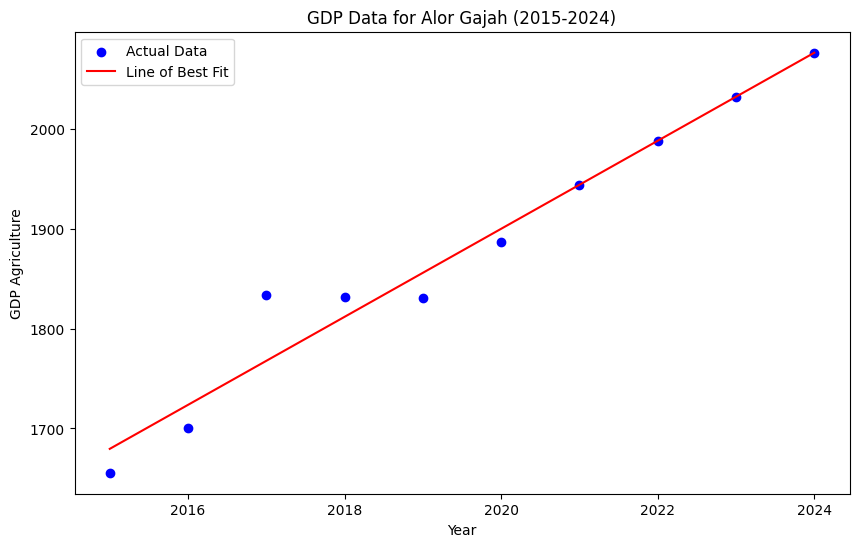

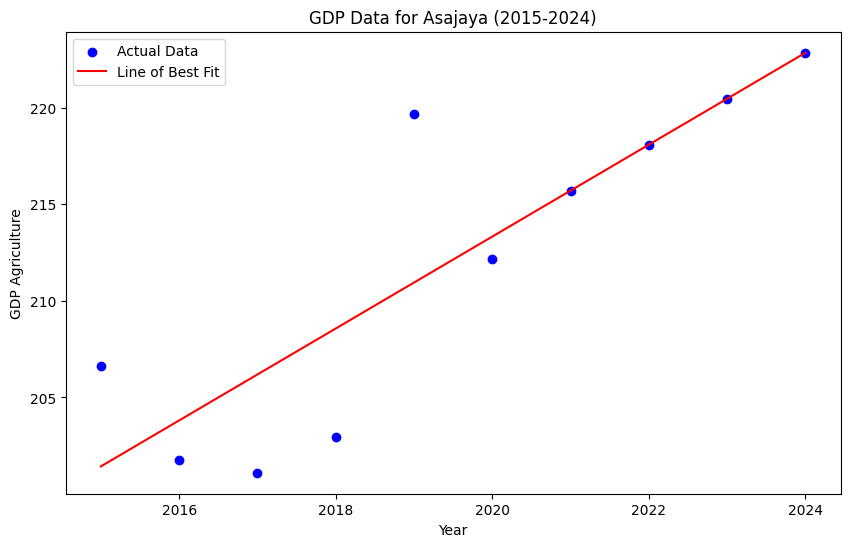

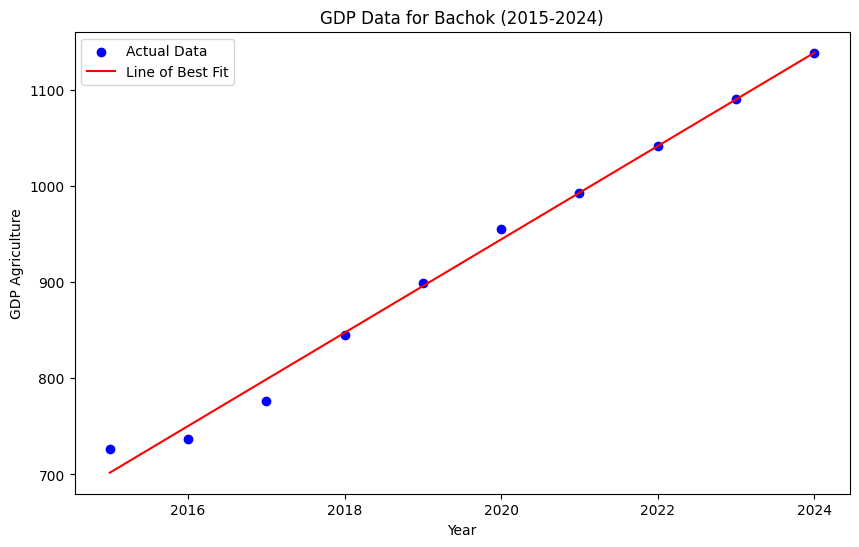

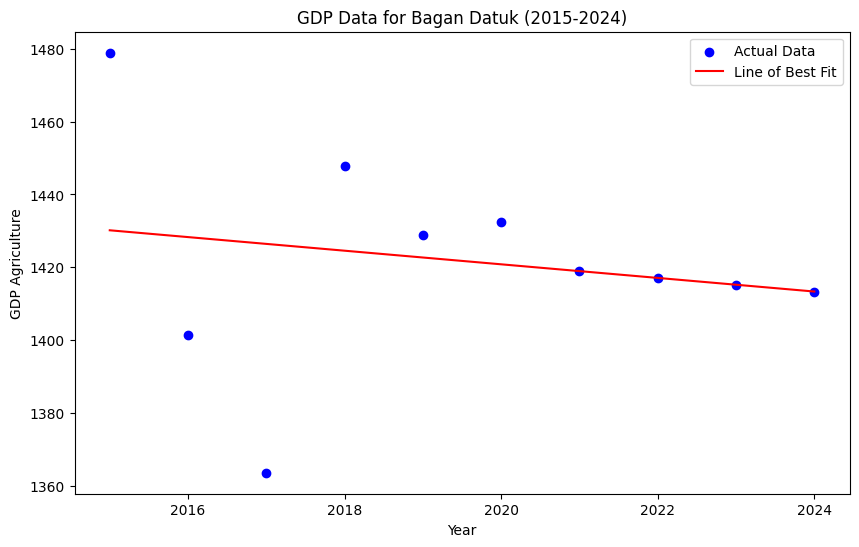

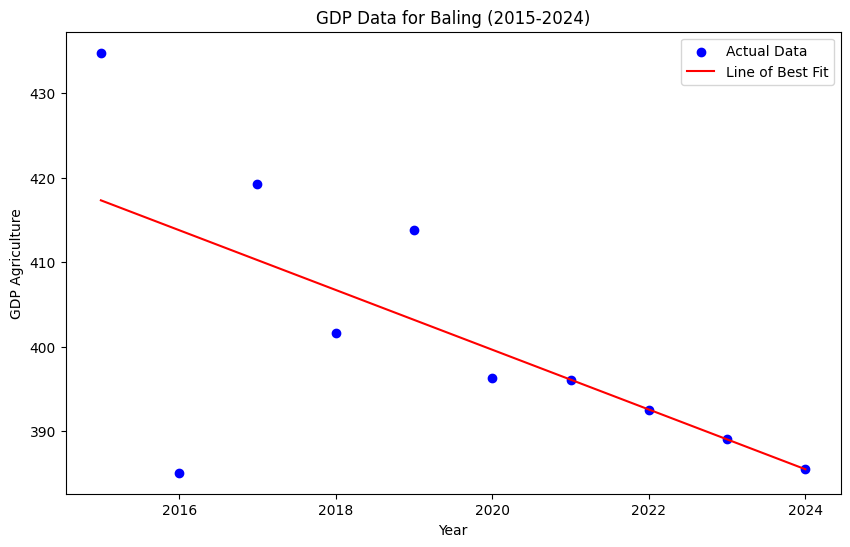

In [215]:
# Extrapolate missing values for gdp_agriculture, gdp_manufacturing, and gdp_services
sectors = ['gdp_agriculture', 'gdp_manufacturing', 'gdp_services']
for sector in sectors:
    # Filter out rows with missing values in the specified sector
    missing_rows = df_gdp[df_gdp[sector].isna()]
    for _, row in missing_rows.iterrows():
        state = row['state']
        district = row['district']
        year = row['year']
        # Filter out rows for the same state and district before the missing year
        past_data = df_gdp[(df_gdp['state'] == state) & (df_gdp['district'] == district) & (df_gdp['year'] < year)]
        # Ensure there is enough past data to train the model
        if len(past_data) > 1:
            X = past_data['year'].values.reshape(-1, 1)
            y = past_data[sector].values
            model = LinearRegression()
            model.fit(X, y)
            # Predict the missing value
            prediction = model.predict(np.array([[year]]))[0]
            # Fill the missing value
            df_gdp.loc[(df_gdp['year'] == year) & (df_gdp['state'] == state) & (df_gdp['district'] == district), sector] = prediction

# Plot the line of best fit for 5 districts
first_5_districts = df_gdp['district'].unique()[:5]
for district in first_5_districts:
    district_data = df_gdp[(df_gdp['district'] == district) & (df_gdp['year'] <= 2024)]
    plt.figure(figsize=(10, 6))
    plt.scatter(district_data['year'], district_data['gdp_agriculture'], color='blue', label='Actual Data')
    
    # Fit the model again for plotting
    model = LinearRegression()
    model.fit(district_data['year'].values.reshape(-1, 1), district_data['gdp_agriculture'].values)
    plt.plot(district_data['year'], model.predict(district_data['year'].values.reshape(-1, 1)), color='red', label='Line of Best Fit')
    
    plt.title(f'GDP Data for {district} (2015-2024)')
    plt.xlabel('Year')
    plt.ylabel('GDP Agriculture')
    plt.legend()
    plt.show()


## Final Check

In [216]:
df_gdp.isna().sum()

state                0
district             0
year                 0
gdp_purchasers       0
gdp_agriculture      0
gdp_manufacturing    0
gdp_services         0
dtype: int64

In [218]:
df_gdp.year.unique()

array([2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024],
      dtype=int64)

In [219]:
len(df_gdp.district.unique()), df_gdp.district.unique()[:3], df_gdp.district.unique()[-3:]

(160,
 array(['Alor Gajah', 'Asajaya', 'Bachok'], dtype=object),
 array(['W.P. Kuala Lumpur', 'W.P. Labuan', 'Yan'], dtype=object))

In [220]:
# Is the data from 2015 to 2024? - Yes
# Is the data of districts 'Alor Gajah', 'Ampang Jaya', 'Arau', ..., 'W.P. Putrajaya', 'Wangsa Maju', 'Yan'? - No, missing data expected
# Can the data be joined by district and year, while retaining the same length? - Yes, but with missingness

In [221]:
df_gdp.to_csv('../data/massaged/gdp.csv', index=False)

In [ ]:
# Split features and target
X = df_gdp[['year', 'gdp_agriculture', 'gdp_manufacturing', 'gdp_services']]
y = df_gdp['gdp_purchasers']

# Split into train and test sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale the features
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train multiple models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)
lr_mse = mean_squared_error(y_test, lr_pred)
lr_r2 = r2_score(y_test, lr_pred)

# Random Forest
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)
rf_pred = rf_model.predict(X_test_scaled)
rf_mse = mean_squared_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred)

# Print results
print("Linear Regression Results:")
print(f"MSE: {lr_mse:.2f}")
print(f"RMSE: {np.sqrt(lr_mse):.2f}")
print(f"R2 Score: {lr_r2:.4f}\n")

print("Random Forest Results:")
print(f"MSE: {rf_mse:.2f}")
print(f"RMSE: {np.sqrt(rf_mse):.2f}") 
print(f"R2 Score: {rf_r2:.4f}")

# Feature importance for Random Forest
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rf_model.feature_importances_
})
print("\nFeature Importance:")
print(feature_importance.sort_values('importance', ascending=False))

# Visualize actual vs predicted values
plt.figure(figsize=(10, 6))
plt.scatter(y_test, rf_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual GDP')
plt.ylabel('Predicted GDP')
plt.title('Random Forest: Actual vs Predicted GDP')
plt.tight_layout()
plt.show()
